# Modelos de clasificación para detección temprana de fraude en entidades bancarias
## Notebook 05 — Ensamble

Sigue el código de clase *Ingeniería de variables + Ensambles*, que combina con **voto suave** (`VotingClassifier(voting="soft")`) un *Bagging* de Regresión Logística y el mejor XGBoost.

En lugar de volver a buscar hiperparámetros, se **reutilizan los mejores modelos de los notebooks 02, 03 y 04** (archivos `.pkl` en `artefactos/`):

1. **Torneo de modelos:** AUC de validación cruzada de cada modelo individual y de varios ensambles, **sobre los mismos folds**, para compararlos en igualdad de condiciones.
2. **Estabilidad** del ensamble ganador: Metodología 1 (*fit train → predict test*) y Metodología 2 (*fit test → predict train*).
3. **Entrenamiento completo** sin balanceo y con balanceo (SMOTE + undersampling).
4. **Análisis de sensibilidad con `pos_ID`** y **predicciones para Kaggle**.

**¿Por qué un ensamble?** Cada modelo se equivoca de forma distinta: la Regresión Logística ve relaciones lineales, Random Forest promedia árboles profundos (baja varianza) y XGBoost corrige errores árbol por árbol (bajo sesgo). Con **voto suave** el ensamble promedia las **probabilidades** de fraude de cada modelo; si los errores no están muy correlacionados, el promedio ordena mejor a los clientes y la AUC sube.

**Bagging de Regresión Logística (como en clase):** se entrenan 20 regresiones logísticas, cada una con una muestra aleatoria del 80% de los datos, y se promedian. Reduce la varianza de la logística.

## 0. Librerías y configuración

In [1]:
import os, sys, json, time, pickle
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import BaggingClassifier, VotingClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix, precision_score, recall_score, f1_score)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

SEMILLA = 20042021
N_JOBS = 4             # procesos en paralelo; con -1 Docker se queda sin memoria
FRAC_TORNEO = 0.20     # fracción (estratificada) de los datos para el torneo de validación cruzada

In [2]:
if "google.colab" in sys.modules:
    DATA_DIR, ART_DIR = "/content/data/", "/content/artefactos/"
elif "DATABRICKS_RUNTIME_VERSION" in os.environ:
    DATA_DIR, ART_DIR = "/Volumes/main/default/fraude/", "/Volumes/main/default/fraude/artefactos/"
else:
    # Docker / local: busca la carpeta data/ (con train.csv) aquí o en las carpetas de arriba
    carpeta = os.path.abspath(".")
    while not os.path.exists(os.path.join(carpeta, "data", "train.csv")) and carpeta != os.path.dirname(carpeta):
        carpeta = os.path.dirname(carpeta)
    DATA_DIR = os.path.join(carpeta, "data", "")
    ART_DIR = "./artefactos/"
SUB_DIR = "./submissions/"
os.makedirs(ART_DIR, exist_ok=True)
os.makedirs(SUB_DIR, exist_ok=True)
DATA_DIR

'/work/s2/metodos_supervisados/data/'

## 1. Base de modelamiento (Notebook 01) y mejores modelos (Notebooks 02 a 04)

In [3]:
base_modelo = pd.read_parquet(ART_DIR + "base_modelo_train.parquet")
base_modelo_prueba = pd.read_parquet(ART_DIR + "base_modelo_test.parquet")

covariables = [x for x in base_modelo.columns if x not in ["Fraude"]]
X = base_modelo.get(covariables).copy()
y = base_modelo["Fraude"].copy()
X_prueba = base_modelo_prueba.get(covariables).copy()

print("Entrenamiento:", X.shape, "| Test Kaggle:", X_prueba.shape)
print(f"Tasa de fraude: {100*y.mean():.2f}%")
print("Covariables:", covariables)

Entrenamiento: (848548, 22) | Test Kaggle: (200027, 22)
Tasa de fraude: 5.99%
Covariables: ['Num_Tarjetas', 'Balance_Tj', 'Total_Transac', 'Trans_Int', 'Estado_LB', 'Genero_LB', 'Tipo_Tarjeta_LB', 'Balance_Tj_2', 'Total_Transac_2', 'Num_Tarjetas_2', 'Num_Tarjetas_Balance_Tj', 'Num_Tarjetas_Total_Transac', 'Balance_Tj_Total_Transac', 'Num_Tarjetas_coc_Balance_Tj', 'Balance_Tj_coc_Num_Tarjetas', 'Total_Transac_coc_Num_Tarjetas', 'Genero_Tipo_Tarjeta=Female_Visa', 'Genero_Tipo_Tarjeta=Male_MasterCard', 'Genero_Tipo_Tarjeta=Female_Discover', 'Balance_Tj_x_Genero=Male', 'Num_Tarjetas_x_Genero=Male', 'Balance_Tj_x_Tipo_Tarjeta=MasterCard']


In [4]:
# Mejores modelos guardados por los notebooks 02, 03 y 04 (pipelines ya entrenados)
nombres = {"logistica": "Regresión Logística", "rforest": "Random Forest", "xgboost": "XGBoost"}
modelos_guardados = {}
for m in nombres:
    for b in ["no_balanceo", "balanceo"]:
        with open(ART_DIR + f"modelo_{m}_{b}.pkl", "rb") as f:
            modelos_guardados[(m, b)] = pickle.load(f)

claves = ["C", "n_estimators", "max_depth", "min_samples_leaf", "max_features", "max_samples",
          "min_child_weight", "learning_rate", "subsample", "colsample_bytree"]
pd.DataFrame([{"Modelo": nombres[m], "Balanceo": b,
               "Hiperparámetros": {k: v for k, v in p.named_steps["modelo"].get_params().items() if k in claves}}
              for (m, b), p in modelos_guardados.items()])

,Modelo,Balanceo,Hiperparámetros
0,Regresión Logística,no_balanceo,{'C': 5}
1,Regresión Logística,balanceo,{'C': 0.5}
2,Random Forest,no_balanceo,"{'max_depth': 15, 'max_features': 0.3, 'max_sa..."
3,Random Forest,balanceo,"{'max_depth': 10, 'max_features': 'sqrt', 'max..."
4,XGBoost,no_balanceo,"{'colsample_bytree': 0.8, 'learning_rate': 0.0..."
5,XGBoost,balanceo,"{'colsample_bytree': 0.6, 'learning_rate': 0.0..."


## 2. Funciones de apoyo
- `componente(m, b)`: crea una **copia sin entrenar** (`clone`) del mejor modelo `m` con sus hiperparámetros, con escalado MinMax y **sin** el paso de balanceo (el balanceo se aplica una sola vez, por fuera del ensamble).
- `crear_ensamble(...)`: arma el `VotingClassifier` de voto suave. Con `balanceo=True` el ensamble completo va dentro de un `Pipeline` con SMOTE + undersampling, igual que en clase (primero se balancea, luego se entrena el ensamble), pero **dentro de cada fold** para que la validación use datos reales.
- `predicciones(...)`: la misma función de los notebooks anteriores (matriz de confusión, curva ROC, AUC con probabilidades y con 0/1).

In [5]:
def componente(m, b="no_balanceo", n_jobs=N_JOBS):
    modelo = clone(modelos_guardados[(m, b)].named_steps["modelo"])
    if "n_jobs" in modelo.get_params():
        modelo.set_params(n_jobs=n_jobs)
    return Pipeline([("escalado", MinMaxScaler()), ("modelo", modelo)])

def bagging_logistica(b="no_balanceo"):
    # Bagging de clase: 20 regresiones logísticas, cada una con el 80% de los registros
    return BaggingClassifier(estimator=componente("logistica", b), n_estimators=20, max_samples=0.8,
                             max_features=1.0, n_jobs=N_JOBS, random_state=SEMILLA)

def crear_ensamble(miembros, balanceo=False):
    b = "balanceo" if balanceo else "no_balanceo"
    fabrica = {"bag_log": lambda: bagging_logistica(b), "log": lambda: componente("logistica", b),
               "rf": lambda: componente("rforest", b), "xgb": lambda: componente("xgboost", b)}
    voto = VotingClassifier(estimators=[(m, fabrica[m]()) for m in miembros], voting="soft", n_jobs=1)
    if not balanceo:
        return voto
    return ImbPipeline([("over", SMOTE(sampling_strategy="not majority", random_state=SEMILLA)),
                        ("under", RandomUnderSampler(sampling_strategy="not minority", replacement=True, random_state=SEMILLA)),
                        ("ensamble", voto)])

def umbral_youden(y_true, proba):
    # Umbral que maximiza TPR - FPR (punto de la curva ROC más alejado de la diagonal)
    fpr, tpr, thr = roc_curve(y_true, proba)
    return thr[np.argmax(tpr - fpr)]

def predicciones(modelo, X_eval, y_eval, titulo="", umbral=None):
    proba = modelo.predict_proba(X_eval)[:, 1]
    auc_proba = roc_auc_score(y_eval, proba)
    auc_01 = roc_auc_score(y_eval, (proba >= 0.5).astype(int))
    if umbral is None:
        umbral = umbral_youden(y_eval, proba)
    yhat = (proba >= umbral).astype(int)

    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    sns.heatmap(pd.DataFrame(confusion_matrix(y_eval, yhat)), annot=True, fmt=",.0f", cmap="Blues", ax=ax[0], cbar=False)
    ax[0].set_title(f"Matriz de confusión (umbral = {umbral:.3f})")
    ax[0].set_xlabel("Valores predichos"); ax[0].set_ylabel("Valores observados")
    fpr, tpr, _ = roc_curve(y_eval, proba)
    ax[1].plot(fpr, tpr, color="#C44E52", lw=2, label=f"Probabilidades: AUC = {auc_proba:.4f}")
    fpr2, tpr2, _ = roc_curve(y_eval, (proba >= 0.5).astype(int))
    ax[1].plot(fpr2, tpr2, color="gray", lw=1.5, ls=":", marker="o", label=f"Solo 0/1 (predict): AUC = {auc_01:.4f}")
    ax[1].plot([0, 1], [0, 1], color="lightgray", ls="--")
    ax[1].set_xlabel("FPR (falsas alarmas)"); ax[1].set_ylabel("TPR (recall / sensibilidad)")
    ax[1].set_title("Curva ROC"); ax[1].legend(loc="lower right")
    fig.suptitle(titulo, fontsize=13); plt.tight_layout(); plt.show()

    res = {"AUC": auc_proba, "AUC_0_1": auc_01, "umbral": umbral,
           "Recall": recall_score(y_eval, yhat), "Precision": precision_score(y_eval, yhat), "F1": f1_score(y_eval, yhat)}
    print(f"AUC (probabilidades) = {auc_proba:.4f} | AUC (0/1 con predict) = {auc_01:.4f}")
    print(f"Con umbral {umbral:.3f}: Recall = {res['Recall']:.3f} | Precision = {res['Precision']:.3f} | F1 = {res['F1']:.3f}")
    return res

## 3. Torneo: modelos individuales vs ensambles (mismos folds)
Todos los candidatos se evalúan con **la misma submuestra estratificada** (`FRAC_TORNEO` de la base) y **los mismos 3 folds** (`StratifiedKFold`), así las diferencias de AUC se deben al modelo y no a los datos.

| Candidato | Composición |
|---|---|
| Ensamble de clase | Bagging de Regresión Logística + XGBoost |
| Ensamble árboles | Random Forest + XGBoost |
| Ensamble completo | Regresión Logística + Random Forest + XGBoost |

In [6]:
%%time
candidatos = {
    "Regresión Logística":                       componente("logistica"),
    "Random Forest":                             componente("rforest"),
    "XGBoost":                                   componente("xgboost"),
    "Ensamble de clase (Bagging Log. + XGB)":    crear_ensamble(["bag_log", "xgb"]),
    "Ensamble árboles (RF + XGB)":               crear_ensamble(["rf", "xgb"]),
    "Ensamble completo (Log. + RF + XGB)":       crear_ensamble(["log", "rf", "xgb"]),
}
X_sub, _, y_sub, _ = train_test_split(X, y, train_size=FRAC_TORNEO, stratify=y, random_state=SEMILLA)
cv3 = StratifiedKFold(3, shuffle=True, random_state=SEMILLA)

auc_folds = {}
for nombre, modelo in candidatos.items():
    t0 = time.time()
    auc_folds[nombre] = cross_val_score(modelo, X_sub, y_sub, scoring="roc_auc", cv=cv3)
    print(f"{nombre:<42} AUC CV = {auc_folds[nombre].mean():.4f} ± {auc_folds[nombre].std():.4f}  ({time.time()-t0:.0f} s)")

torneo = pd.DataFrame({"AUC CV (media)": {k: v.mean() for k, v in auc_folds.items()},
                       "AUC CV (desv.)": {k: v.std() for k, v in auc_folds.items()}}).sort_values("AUC CV (media)", ascending=False)
torneo.round(4)

Regresión Logística                        AUC CV = 0.9216 ± 0.0025  (2 s)


Random Forest                              AUC CV = 0.9288 ± 0.0023  (15 s)


XGBoost                                    AUC CV = 0.9316 ± 0.0021  (2 s)


Ensamble de clase (Bagging Log. + XGB)     AUC CV = 0.9289 ± 0.0023  (7 s)


Ensamble árboles (RF + XGB)                AUC CV = 0.9311 ± 0.0022  (19 s)


Ensamble completo (Log. + RF + XGB)        AUC CV = 0.9297 ± 0.0023  (22 s)
CPU times: user 4min 27s, sys: 607 ms, total: 4min 27s
Wall time: 1min 7s


,AUC CV (media),AUC CV (desv.)
XGBoost,0.9316,0.0021
Ensamble árboles (RF + XGB),0.9311,0.0022
Ensamble completo (Log. + RF + XGB),0.9297,0.0023
Ensamble de clase (Bagging Log. + XGB),0.9289,0.0023
Random Forest,0.9288,0.0023
Regresión Logística,0.9216,0.0025


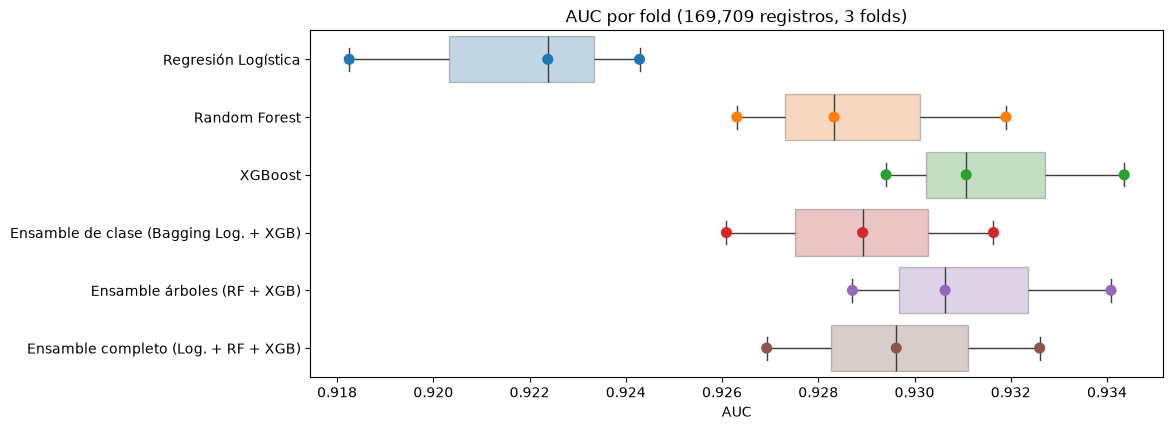

Ensamble elegido: Ensamble árboles (RF + XGB) -> ['rf', 'xgb']


In [7]:
folds_torneo = pd.DataFrame(auc_folds)
plt.figure(figsize=(11, 4.5))
sns.stripplot(data=folds_torneo, size=8, jitter=False, orient="h"); sns.boxplot(data=folds_torneo, boxprops={"alpha": 0.3}, orient="h")
plt.title(f"AUC por fold ({len(X_sub):,} registros, 3 folds)"); plt.xlabel("AUC"); plt.show()

ensambles = [k for k in torneo.index if k.startswith("Ensamble")]
GANADOR = ensambles[0]   # el ensamble con mayor AUC CV
miembros = {"Ensamble de clase (Bagging Log. + XGB)": ["bag_log", "xgb"],
            "Ensamble árboles (RF + XGB)": ["rf", "xgb"],
            "Ensamble completo (Log. + RF + XGB)": ["log", "rf", "xgb"]}[GANADOR]
print("Ensamble elegido:", GANADOR, "->", miembros)

## 4. Estabilidad del ensamble elegido (50% / 50%, estratificado)

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=19052023, stratify=y)
print("Train:", X_train.shape, f"fraude {100*y_train.mean():.2f}%")
print("Test: ", X_test.shape, f"fraude {100*y_test.mean():.2f}%")

Train: (424274, 22) fraude 5.99%
Test:  (424274, 22) fraude 5.99%


## Metodología 1: *fit train → predict test*

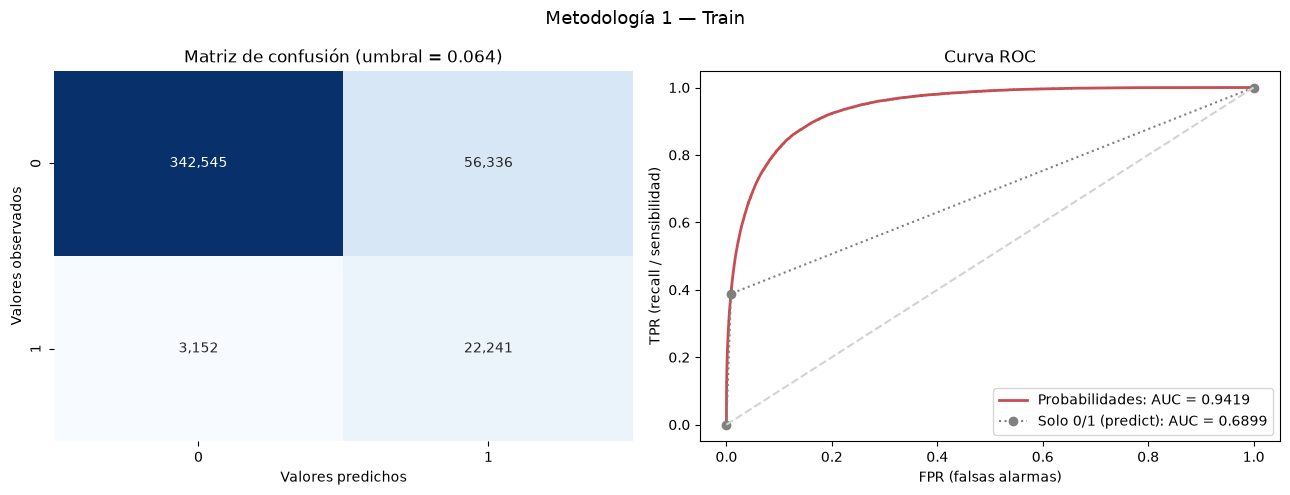

AUC (probabilidades) = 0.9419 | AUC (0/1 con predict) = 0.6899
Con umbral 0.064: Recall = 0.876 | Precision = 0.283 | F1 = 0.428


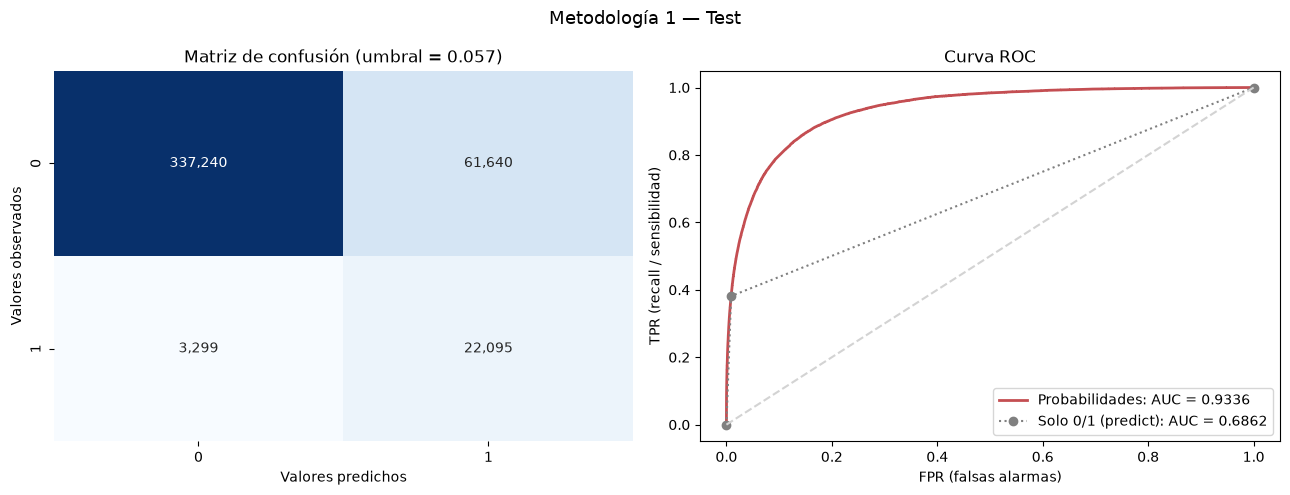

AUC (probabilidades) = 0.9336 | AUC (0/1 con predict) = 0.6862
Con umbral 0.057: Recall = 0.870 | Precision = 0.264 | F1 = 0.405
CPU times: user 2min 16s, sys: 246 ms, total: 2min 16s
Wall time: 35.5 s


In [9]:
%%time
ens1 = crear_ensamble(miembros).fit(X_train, y_train)
res1_train = predicciones(ens1, X_train, y_train, "Metodología 1 — Train")
res1_test = predicciones(ens1, X_test, y_test, "Metodología 1 — Test")

## Metodología 2: *fit test → predict train*

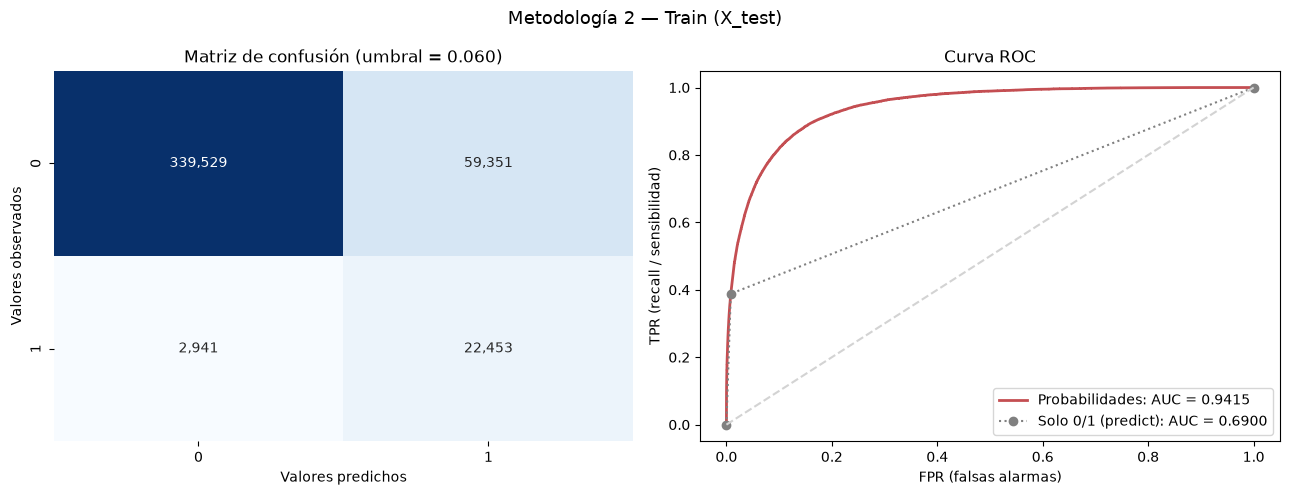

AUC (probabilidades) = 0.9415 | AUC (0/1 con predict) = 0.6900
Con umbral 0.060: Recall = 0.884 | Precision = 0.274 | F1 = 0.419


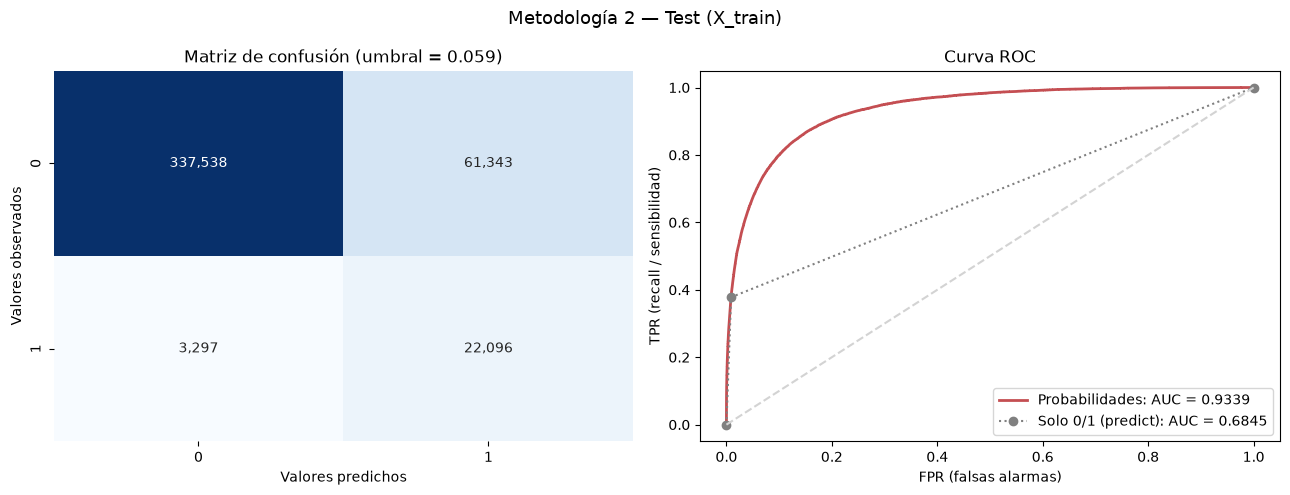

AUC (probabilidades) = 0.9339 | AUC (0/1 con predict) = 0.6845
Con umbral 0.059: Recall = 0.870 | Precision = 0.265 | F1 = 0.406
CPU times: user 2min 17s, sys: 139 ms, total: 2min 17s
Wall time: 35.5 s


In [10]:
%%time
ens2 = crear_ensamble(miembros).fit(X_test, y_test)
res2_train = predicciones(ens2, X_test, y_test, "Metodología 2 — Train (X_test)")
res2_test = predicciones(ens2, X_train, y_train, "Metodología 2 — Test (X_train)")

In [11]:
estabilidad = pd.DataFrame([
    {"Metodología": n, "AUC Train": rt["AUC"], "AUC Test": rs["AUC"], "Brecha Train-Test": rt["AUC"] - rs["AUC"], "AUC Test con 0/1": rs["AUC_0_1"]}
    for n, rt, rs in [("1: fit train → predict test", res1_train, res1_test), ("2: fit test → predict train", res2_train, res2_test)]])
estabilidad.round(4)

,Metodología,AUC Train,AUC Test,Brecha Train-Test,AUC Test con 0/1
0,1: fit train → predict test,0.9419,0.9336,0.0083,0.6862
1,2: fit test → predict train,0.9415,0.9339,0.0076,0.6845


# 5. Entrenamiento completo
Se entrena el ensamble elegido con **toda** la base, sin balanceo y con balanceo (SMOTE + undersampling antes del ensamble, como en clase). La AUC CV del ensamble balanceado se calcula sobre la misma submuestra y folds del torneo.

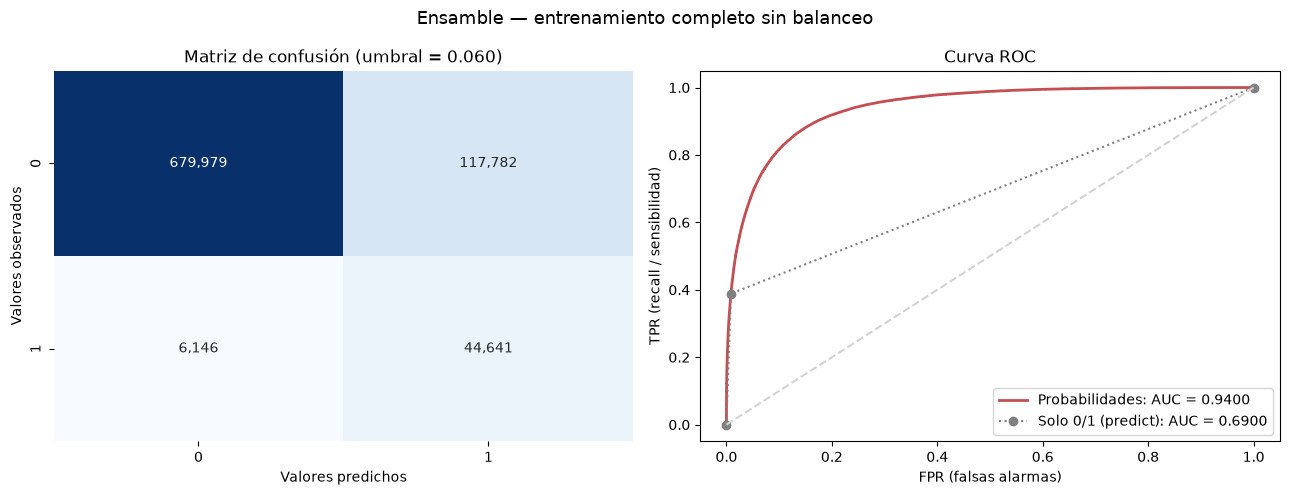

AUC (probabilidades) = 0.9400 | AUC (0/1 con predict) = 0.6900
Con umbral 0.060: Recall = 0.879 | Precision = 0.275 | F1 = 0.419
CPU times: user 4min 38s, sys: 411 ms, total: 4min 39s
Wall time: 1min 11s


In [12]:
%%time
Ensamble_BE = crear_ensamble(miembros).fit(X, y)
res_SB = predicciones(Ensamble_BE, X, y, "Ensamble — entrenamiento completo sin balanceo")

AUC CV con balanceo: 0.9231 ± 0.0021


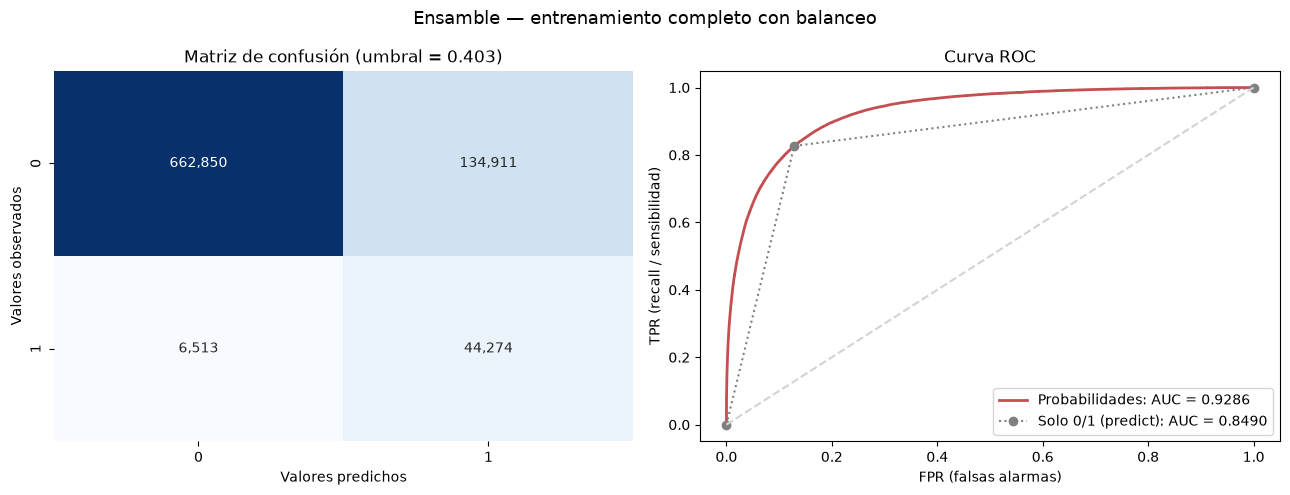

AUC (probabilidades) = 0.9286 | AUC (0/1 con predict) = 0.8490
Con umbral 0.403: Recall = 0.872 | Precision = 0.247 | F1 = 0.385
CPU times: user 5min 59s, sys: 1.33 s, total: 6min
Wall time: 1min 32s


In [13]:
%%time
auc_cv_balanceo = cross_val_score(crear_ensamble(miembros, balanceo=True), X_sub, y_sub, scoring="roc_auc", cv=cv3)
print(f"AUC CV con balanceo: {auc_cv_balanceo.mean():.4f} ± {auc_cv_balanceo.std():.4f}")
Ensamble_BE_Balanced = crear_ensamble(miembros, balanceo=True).fit(X, y)
res_B = predicciones(Ensamble_BE_Balanced, X, y, "Ensamble — entrenamiento completo con balanceo")

In [14]:
comparacion = pd.DataFrame([
    {"Modelo": "Sin balanceo", "AUC CV (media)": auc_folds[GANADOR].mean(), "AUC CV (desv.)": auc_folds[GANADOR].std(), **res_SB},
    {"Modelo": "Con balanceo", "AUC CV (media)": auc_cv_balanceo.mean(), "AUC CV (desv.)": auc_cv_balanceo.std(), **res_B},
]).set_index("Modelo")
comparacion.round(4)

,AUC CV (media),AUC CV (desv.),AUC,AUC_0_1,umbral,Recall,Precision,F1
Modelo,,,,,,,,
Sin balanceo,0.9311,0.0022,0.9400,0.690,0.0601,0.8790,0.2748,0.4188
Con balanceo,0.9231,0.0021,0.9286,0.849,0.4029,0.8718,0.2471,0.3850


# Análisis de sensibilidad: efecto del orden del `ID`
Igual que en los notebooks anteriores, se agrega `pos_ID` (posición relativa del cliente dentro de su grupo Estado–Género–Tipo de tarjeta) y se compara la AUC CV con la misma submuestra y folds.

In [15]:
grupo = ["Estado", "Genero", "Tipo_Tarjeta"]
crudo = pd.concat([pd.read_csv(DATA_DIR + "train.csv", sep=";", usecols=["ID"] + grupo),
                   pd.read_csv(DATA_DIR + "test.csv",  sep=";", usecols=["ID"] + grupo)])
crudo["pos_ID"] = crudo.groupby(grupo)["ID"].rank(pct=True)
pos = crudo.set_index("ID")["pos_ID"]

ids_train = pd.read_csv(DATA_DIR + "train.csv", sep=";", usecols=["ID"])["ID"]
X_id = X.copy();               X_id["pos_ID"] = pos.loc[ids_train].values
X_prueba_id = X_prueba.copy(); X_prueba_id["pos_ID"] = pos.loc[base_modelo_prueba["ID"]].values

In [16]:
%%time
X_sub_id = X_id.loc[X_sub.index]
auc_cv_id = cross_val_score(crear_ensamble(miembros), X_sub_id, y_sub, scoring="roc_auc", cv=cv3)
print(f"AUC CV sin pos_ID: {auc_folds[GANADOR].mean():.4f}")
print(f"AUC CV con pos_ID: {auc_cv_id.mean():.4f} ± {auc_cv_id.std():.4f}")
Ensamble_ID = crear_ensamble(miembros).fit(X_id, y)

AUC CV sin pos_ID: 0.9311
AUC CV con pos_ID: 0.9568 ± 0.0016


CPU times: user 7min 8s, sys: 428 ms, total: 7min 8s
Wall time: 1min 48s


# Predicciones nuevos datos (Kaggle)
Formato del `sample_submission.csv`: columnas `ID` y `Fraude`, separadas por coma. En `Fraude` se sube la **probabilidad** de fraude.

In [17]:
def guardar_submission(proba, nombre):
    evaluacion = pd.DataFrame({"ID": base_modelo_prueba["ID"].values, "Fraude": proba})
    evaluacion.to_csv(SUB_DIR + nombre, index=False, sep=",")
    print(f"{nombre}: {len(evaluacion):,} filas | probabilidad media = {evaluacion['Fraude'].mean():.4f}")
    return evaluacion

sub_SB = guardar_submission(Ensamble_BE.predict_proba(X_prueba)[:, 1],          "submission_ensamble_no_balanceo.csv")
sub_B  = guardar_submission(Ensamble_BE_Balanced.predict_proba(X_prueba)[:, 1], "submission_ensamble_balanceo.csv")
sub_ID = guardar_submission(Ensamble_ID.predict_proba(X_prueba_id)[:, 1],       "submission_ensamble_con_posID.csv")
sub_SB.head()

submission_ensamble_no_balanceo.csv: 200,027 filas | probabilidad media = 0.0598


submission_ensamble_balanceo.csv: 200,027 filas | probabilidad media = 0.2245


submission_ensamble_con_posID.csv: 200,027 filas | probabilidad media = 0.0599


,ID,Fraude
0,9,0.014206
1,11,0.003731
2,19,0.007587
3,20,0.014625
4,22,0.004257


In [18]:
# Validación del formato contra la plantilla de Kaggle
plantilla = pd.read_csv(DATA_DIR + "sample_submission.csv")
for s in [sub_SB, sub_B, sub_ID]:
    assert list(s.columns) == list(plantilla.columns) and (s["ID"].values == plantilla["ID"].values).all()
    assert s["Fraude"].between(0, 1).all() and s["Fraude"].notnull().all()
print("✔ Los archivos tienen el mismo formato e IDs que sample_submission.csv")

✔ Los archivos tienen el mismo formato e IDs que sample_submission.csv


## Guardar modelos y resultados (para el Notebook 06 de comparación)

In [19]:
with open(ART_DIR + "modelo_ensamble_no_balanceo.pkl", "wb") as f: pickle.dump(Ensamble_BE, f)
with open(ART_DIR + "modelo_ensamble_balanceo.pkl", "wb") as f:    pickle.dump(Ensamble_BE_Balanced, f)

resultados = {
    "modelo": "Ensamble",
    "ensamble_elegido": GANADOR,
    "torneo": torneo.reset_index(names="Candidato").to_dict(orient="records"),
    "folds_torneo": folds_torneo.to_dict(orient="list"),
    "estabilidad": estabilidad.to_dict(orient="records"),
    "completo": comparacion.reset_index().to_dict(orient="records"),
    "auc_cv_con_posID": auc_cv_id.mean(),
}
with open(ART_DIR + "resultados_ensamble.json", "w", encoding="utf-8") as f:
    json.dump(resultados, f, ensure_ascii=False, indent=2, default=float)
print(sorted(os.listdir(ART_DIR)))

['base_modelo_test.parquet', 'base_modelo_train.parquet', 'modelo_ensamble_balanceo.pkl', 'modelo_ensamble_no_balanceo.pkl', 'modelo_logistica_balanceo.pkl', 'modelo_logistica_no_balanceo.pkl', 'modelo_rforest_balanceo.pkl', 'modelo_rforest_no_balanceo.pkl', 'modelo_xgboost_balanceo.pkl', 'modelo_xgboost_no_balanceo.pkl', 'receta_variables.json', 'resultados_ensamble.json', 'resultados_logistica.json', 'resultados_rforest.json', 'resultados_xgboost.json']


## Conclusiones

_(se completa tras revisar los resultados)_